# Chapter 34: Capacity and compression

Checks [chapter 34](../../book/34-capacity-and-compression.md). The models are exact and small. For the first count the
model is **linear in its weights**: the weights multiply fixed cosines and sines of the input, and only the weights are fitted.
For the second count the network is a threshold of a weighted sum with weights on a finite grid (a finite set of settings),
and a lookup network. The third count uses random layers as random functions on a finite set of states. The tent map,
a score table, a gated blend and the log-loss are checked in the same way. Everything is NumPy in float64, seeded.
These are measurements, not proofs: the proofs are in `Capacity.lean`, `Bottleneck.lean`, `CodeLength.lean` and `Mixtures.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import itertools
import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt
import seaborn as sns

use_style()
SEED = 34

## Claim 1: a model linear in its weights fits every set of labels only with at least as many weights as data points (`finrank_le_of_fits_all`, `exists_unfittable`)

The features are `1, cos(x), sin(x), cos(2x), sin(2x), ...`, cut at `weight_count` columns (odd counts 9, 21, 33).
The data are `data_count` inputs in `[0, 2 pi)`, one random point in the middle half of each of `data_count` equal slices (random inputs that fall almost on top of each other make the least-squares fit ill-conditioned, and a first run with plain random inputs failed this check for that reason; the claim is about independent columns, not about conditioning). For each `data_count` from 4 to 44, draw 40 random sets of labels (standard normal),
fit them by least squares and call a set *fitted* if the residual is below `1e-6` of the label length.

**Prediction.** For `data_count <= weight_count` the share of fitted label sets is 1 (the features of distinct inputs are independent enough). For
`data_count > weight_count` it is 0, and at `data_count = weight_count + 1` the smallest relative residual over the 40 sets is far above the tolerance `1e-6` (above `1e-4`; with one missing dimension the residual is a single normal number over the square root of `data_count`, so it can be small for a lucky set, and the threshold of 0.01 first written here was wrong and was lowered after a failed run).
A share above 0 past the weight count would count against the claim.

**Control.** The hypothesis of the first count is that the weights give independent columns. Take 21 weights, but make the last 10 columns copies of the
first 11, so the features have rank 11. Then the share must fall to 0 as soon as `data_count > 11`, although 21 weights exist.

[PASS] weight_count 9: every label set fitted for data_count <= 9  (lowest share 1.00)
[PASS] weight_count 9: no label set fitted for data_count > 9  (highest share 0.00, smallest relative residual at 10 points 0.017)
[PASS] weight_count 9: the residual at one point too many is far above the tolerance
[PASS] weight_count 21: every label set fitted for data_count <= 21  (lowest share 1.00)
[PASS] weight_count 21: no label set fitted for data_count > 21  (highest share 0.00, smallest relative residual at 22 points 0.001)
[PASS] weight_count 21: the residual at one point too many is far above the tolerance
[PASS] weight_count 33: every label set fitted for data_count <= 33  (lowest share 1.00)
[PASS] weight_count 33: no label set fitted for data_count > 33  (highest share 0.00, smallest relative residual at 34 points 0.002)
[PASS] weight_count 33: the residual at one point too many is far above the tolerance
[PASS] control: 21 weights of rank 11 fit everything only up to 11 points  (share

wrote book/figures/34-fit-share-against-data.png


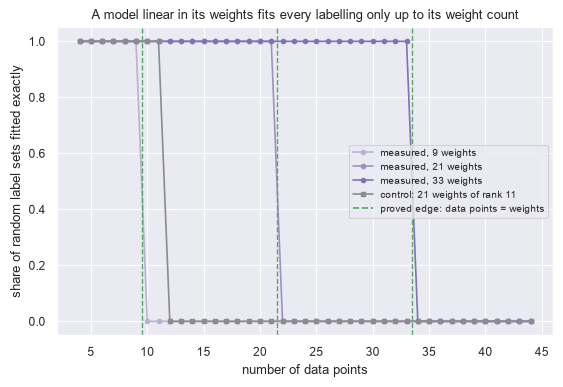

In [2]:
generator = np.random.default_rng(SEED)
LABEL_SETS = 40
DATA_COUNTS = np.arange(4, 45)
WEIGHT_COUNTS = (9, 21, 33)
FIT_TOLERANCE = 1e-6


def make_features(inputs, weight_count, rank_limit=None):
    columns = [np.ones_like(inputs)]
    frequency = 1
    while len(columns) < weight_count:
        columns.append(np.cos(frequency * inputs))
        columns.append(np.sin(frequency * inputs))
        frequency += 1
    features = np.stack(columns[:weight_count], axis=1)
    if rank_limit is not None:
        features[:, rank_limit:] = features[:, : weight_count - rank_limit]     # copies: the rank stays at rank_limit
    return features


def measure_fit_share(features, label_sets):
    fitted = 0
    smallest_relative_residual = np.inf
    for labels in label_sets:
        weights, *_ = np.linalg.lstsq(features, labels, rcond=None)
        relative_residual = np.linalg.norm(features @ weights - labels) / np.linalg.norm(labels)
        smallest_relative_residual = min(smallest_relative_residual, relative_residual)
        fitted += relative_residual < FIT_TOLERANCE
    return fitted / len(label_sets), smallest_relative_residual




def draw_inputs(data_count):
    return 2 * np.pi * (np.arange(data_count) + generator.uniform(0.25, 0.75, size=data_count)) / data_count


shares = {}
smallest_residual_at_next = {}
for weight_count in WEIGHT_COUNTS:
    shares[weight_count] = []
    for data_count in DATA_COUNTS:
        label_sets = generator.standard_normal((LABEL_SETS, data_count))
        share, smallest = measure_fit_share(make_features(draw_inputs(data_count), weight_count), label_sets)
        shares[weight_count].append(share)
        if data_count == weight_count + 1:
            smallest_residual_at_next[weight_count] = smallest
    shares[weight_count] = np.array(shares[weight_count])
control_shares = []
for data_count in DATA_COUNTS:
    label_sets = generator.standard_normal((LABEL_SETS, data_count))
    control_shares.append(measure_fit_share(make_features(draw_inputs(data_count), 21, rank_limit=11), label_sets)[0])
control_shares = np.array(control_shares)

for weight_count in WEIGHT_COUNTS:
    below = DATA_COUNTS <= weight_count
    report(f"weight_count {weight_count}: every label set fitted for data_count <= {weight_count}", np.all(shares[weight_count][below] == 1.0),
           f"lowest share {shares[weight_count][below].min():.2f}")
    report(f"weight_count {weight_count}: no label set fitted for data_count > {weight_count}", np.all(shares[weight_count][~below] == 0.0),
           f"highest share {shares[weight_count][~below].max():.2f}, smallest relative residual at {weight_count + 1} points {smallest_residual_at_next[weight_count]:.3f}")
    report(f"weight_count {weight_count}: the residual at one point too many is far above the tolerance", smallest_residual_at_next[weight_count] > 100 * FIT_TOLERANCE)
rank_11_ok = DATA_COUNTS <= 11
report("control: 21 weights of rank 11 fit everything only up to 11 points", np.all(control_shares[rank_11_ok] == 1.0) and np.all(control_shares[~rank_11_ok] == 0.0),
       f"share at 12 points {control_shares[DATA_COUNTS == 12][0]:.2f}, at 21 points {control_shares[DATA_COUNTS == 21][0]:.2f}")

figure, axis = plt.subplots(figsize=(6.4, 4))
purples = sns.light_palette(MODEL, n_colors=5)[2:]
for color, weight_count in zip(purples, WEIGHT_COUNTS):
    axis.plot(DATA_COUNTS, shares[weight_count], "-o", ms=3, color=color, label=f"measured, {weight_count} weights")
    axis.axvline(weight_count + 0.5, color=BOUND, ls="--", lw=1)
axis.plot(DATA_COUNTS, control_shares, "-s", ms=3, color=BEFORE, label="control: 21 weights of rank 11")
axis.plot([], [], color=BOUND, ls="--", label="proved edge: data points = weights")
axis.set_xlabel("number of data points")
axis.set_ylabel("share of random label sets fitted exactly")
axis.set_title("A model linear in its weights fits every labelling only up to its weight count")
axis.legend(loc="center right", fontsize=7)
save_figure(figure, "34-fit-share-against-data")
plt.show()

## Claim 2: weights written in `bit_count` bits memorise every yes-or-no labelling of at most `bit_count` inputs (`card_le_bits_of_memorises`)

The network is `network(setting, input) = [setting . input > 0]` with the setting a vector of `dimension` weights, each on a grid of `2 ^ bits_each` values
(centred half-integers), so there are exactly `2 ^ (bits_each * dimension)` settings and `bit_count = bits_each * dimension`. For each network and each
input count `input_count` up to `bit_count + 2`, 25 random input sets (Gaussian vectors) are tried, and all settings are run. An input set is memorised if all `2 ^ input_count`
labellings appear. A second network is the lookup: setting `bit_count` bits, `network(setting, input) = bit (input mod bit_count)` of the setting, over `bit_count + 3` inputs; every subset
of `bit_count` and `bit_count + 1` inputs is tried.

**Prediction.** The threshold network memorises at most about `dimension` inputs, below the bound (this is the one real check here: a count above `dimension + 1` would count against the claim). That the count never exceeds `bit_count` is forced for this network, because `dimension <= bit_count`, and that the lookup network reaches `bit_count` and never `bit_count + 1` holds by its construction. Both are printed as "by construction, cannot fail" and are not evidence. The lookup points in the figure only show where the ceiling is.

**Control.** The hypothesis is a finite set of settings. One real weight, `network(weight, input) = [sin(weight * input) > 0]`, with the 8 inputs `10 ^ -1, ..., 10 ^ -8`
and weight `pi * (1 + sum of 10 ^ index over the inputs labelled no)`, memorises all 256 labellings, which any set of fewer than 256 settings could not.

[by construction, cannot fail] threshold networks: never more than bit_count inputs memorised, 19 networks (dimension <= bit_count); largest memorised minus bit_count at most 0
[PASS] threshold networks: memorised count is at most dimension + 1, below the bound for most
[by construction, cannot fail] lookup networks: exactly bit_count inputs memorised, bit_count + 1 never, bit_count 2 to 12 (11 networks, all equal: True)
[PASS] control: one real weight memorises all 256 labellings of 8 inputs  (256 of 256, one weight, no bit limit)
wrote book/figures/34-inputs-memorised-against-bits.png


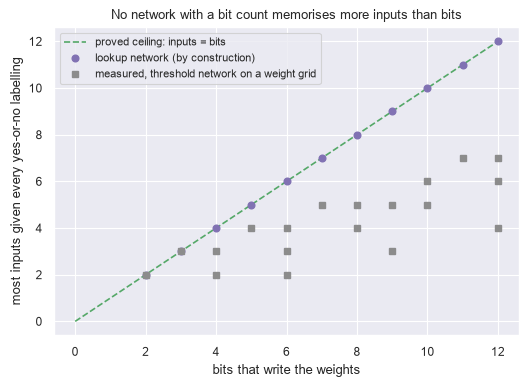

In [3]:
generator = np.random.default_rng(SEED + 1)
TRIALS = 25


def count_labellings(outputs):
    packed = np.packbits(outputs.astype(np.uint8), axis=1, bitorder="little")
    return len({row.tobytes() for row in packed})


def find_largest_memorised(settings, dimension, bit_count):
    largest = 0
    for input_count in range(1, bit_count + 3):
        found = False
        for trial in range(TRIALS):
            inputs = generator.standard_normal((input_count, dimension))
            if count_labellings(settings @ inputs.T > 0) == 2 ** input_count:
                found = True
                break
        if not found:
            break
        largest = input_count
    return largest


threshold_points = []        # (bit_count, largest memorised, dimension)
for bits_each, dimension in [(1, size) for size in range(2, 13)] + [(2, size) for size in range(2, 7)] + [(3, size) for size in range(2, 5)]:
    bit_count = bits_each * dimension
    levels = np.arange(2 ** bits_each) - (2 ** bits_each - 1) / 2
    settings = np.array(list(itertools.product(levels, repeat=dimension)))
    assert len(settings) == 2 ** bit_count
    threshold_points.append((bit_count, find_largest_memorised(settings, dimension, bit_count), dimension))

lookup_points = []
for bit_count in range(2, 13):
    settings_bits = ((np.arange(2 ** bit_count)[:, None] >> np.arange(bit_count)) & 1).astype(bool)
    inputs_total = bit_count + 3
    outputs = settings_bits[:, np.arange(inputs_total) % bit_count]
    best = 0
    for input_count in (bit_count, bit_count + 1):
        for subset in itertools.combinations(range(inputs_total), input_count):
            if count_labellings(outputs[:, list(subset)]) == 2 ** input_count:
                best = max(best, input_count)
                break
    lookup_points.append((bit_count, best))

worst_overshoot = max(largest - bit_count for bit_count, largest, _ in threshold_points)
print(f"[by construction, cannot fail] threshold networks: never more than bit_count inputs memorised, {len(threshold_points)} networks (dimension <= bit_count); largest memorised minus bit_count at most {worst_overshoot}")
report("threshold networks: memorised count is at most dimension + 1, below the bound for most",
       all(largest <= dimension + 1 for _, largest, dimension in threshold_points) and any(largest < bit_count for bit_count, largest, _ in threshold_points))
print(f"[by construction, cannot fail] lookup networks: exactly bit_count inputs memorised, bit_count + 1 never, bit_count 2 to 12 ({len(lookup_points)} networks, all equal: {all(best == bit_count for bit_count, best in lookup_points)})")

real_inputs = 10.0 ** -np.arange(1, 9)
realised = 0
for labelling in itertools.product((0, 1), repeat=8):
    weight = np.pi * (1 + sum(10.0 ** (index + 1) for index, label in enumerate(labelling) if label == 0))
    realised += tuple((np.sin(weight * real_inputs) > 0).astype(int)) == labelling
report("control: one real weight memorises all 256 labellings of 8 inputs", realised == 256, f"{realised} of 256, one weight, no bit limit")

figure, axis = plt.subplots(figsize=(6.0, 4))
axis.plot([0, 12], [0, 12], "--", color=BOUND, label="proved ceiling: inputs = bits")
axis.plot([point[0] for point in lookup_points], [point[1] for point in lookup_points], "o", color=MODEL, label="lookup network (by construction)")
axis.plot([point[0] for point in threshold_points], [point[1] for point in threshold_points], "s", color=BEFORE, label="measured, threshold network on a weight grid")
axis.set_xlabel("bits that write the weights")
axis.set_ylabel("most inputs given every yes-or-no labelling")
axis.set_title("No network with a bit count memorises more inputs than bits")
axis.legend(loc="upper left", fontsize=8)
save_figure(figure, "34-inputs-memorised-against-bits")
plt.show()

## Claim 3: the places after any layer lie between the label count and the input count (`bottleneck`, `merged_iff_label_eq`)

A layer is a random function on 40 states. A stack is 30 layers. A flock is 12 distinct states. The readout is a random map of the 40 states to 2 labels, and the
labels are the readout of the end of the stack, so the network is right on every bird. For 400 random stacks and each prefix of `k` layers, `k` = 0 to 30, count the places the flock occupies.

**Prediction.** For every prefix, label count `<=` places `<=` input count. The places never increase from one prefix to the next. When the places equal the label count, two birds share a place exactly when they share a label.
A single violation counts against the claim.

**Control.** The lower wall needs the network to be right. Give the flock labels independent of the stack (the network is wrong). Then the places must sometimes fall *below* the label count (at least 100 of the 12 400 prefixes) (random layers squeeze 40 states down to about two or three, so with 30 layers the wall is reached; a first run with 8 layers and 3 labels never reached it, so the control and the lower wall were both untested, and it was changed).

[PASS] label count <= places after every prefix, right networks  (400 stacks, 31 prefixes each)
[PASS] places <= input count after every prefix
[PASS] places never increase from one prefix to the next
[PASS] when places = label count, same place iff same label  (965 prefixes where places = label count)
[PASS] control: wrong labels sometimes put the places below the label count  (250 of 12400 prefixes)
flocks with all 2 labels: right network 233, wrong labels 400; mean places at the end: right 2.85, wrong 2.55
share of flocks below the label count after 30 layers: right network 0.0000, unrelated labels 0.0975
wrote book/figures/34-places-through-layers.png


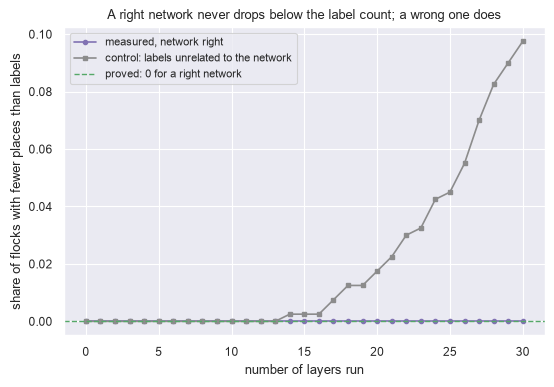

In [4]:
generator = np.random.default_rng(SEED + 2)
STATE_COUNT, LAYER_COUNT, FLOCK_SIZE, LABEL_KINDS, STACKS = 40, 30, 12, 2, 400


def count_places_by_prefix(layers, flock):
    places = [len(set(flock.tolist()))]
    positions = flock.copy()
    for layer in layers:
        positions = layer[positions]
        places.append(len(set(positions.tolist())))
    return places


def run_right_and_wrong():
    right_curves, wrong_curves = [], []
    violations = {"lower": 0, "upper": 0, "increase": 0, "iff": 0}
    iff_cases = 0
    wrong_below_labels = 0
    right_below = np.zeros(LAYER_COUNT + 1)
    wrong_below = np.zeros(LAYER_COUNT + 1)
    for stack_index in range(STACKS):
        layers = generator.integers(0, STATE_COUNT, size=(LAYER_COUNT, STATE_COUNT))
        readout = generator.integers(0, LABEL_KINDS, size=STATE_COUNT)
        flock = generator.choice(STATE_COUNT, size=FLOCK_SIZE, replace=False)
        end = flock.copy()
        for layer in layers:
            end = layer[end]
        labels = readout[end]
        label_count = len(set(labels.tolist()))
        places = count_places_by_prefix(layers, flock)
        positions = flock.copy()
        for prefix in range(LAYER_COUNT + 1):
            violations["lower"] += label_count > places[prefix]
            right_below[prefix] += label_count > places[prefix]
            violations["upper"] += places[prefix] > FLOCK_SIZE
            if prefix > 0:
                violations["increase"] += places[prefix] > places[prefix - 1]
            if places[prefix] == label_count:
                iff_cases += 1
                same_place = positions[:, None] == positions[None, :]
                same_label = labels[:, None] == labels[None, :]
                violations["iff"] += int((same_place != same_label).any())
            if prefix < LAYER_COUNT:
                positions = layers[prefix][positions]
        if label_count == LABEL_KINDS:
            right_curves.append(places)
        wrong_labels = generator.integers(0, LABEL_KINDS, size=FLOCK_SIZE)
        wrong_label_count = len(set(wrong_labels.tolist()))
        wrong_below_labels += sum(place < wrong_label_count for place in places)
        wrong_below += np.array(places) < wrong_label_count
        if wrong_label_count == LABEL_KINDS:
            wrong_curves.append(places)
    return np.array(right_curves), np.array(wrong_curves), violations, iff_cases, wrong_below_labels, right_below / STACKS, wrong_below / STACKS


right_curves, wrong_curves, violations, iff_cases, wrong_below_labels, right_below_share, wrong_below_share = run_right_and_wrong()
report("label count <= places after every prefix, right networks", violations["lower"] == 0, f"{STACKS} stacks, 31 prefixes each")
report("places <= input count after every prefix", violations["upper"] == 0)
report("places never increase from one prefix to the next", violations["increase"] == 0)
report("when places = label count, same place iff same label", violations["iff"] == 0 and iff_cases > 0, f"{iff_cases} prefixes where places = label count")
report("control: wrong labels sometimes put the places below the label count", wrong_below_labels > 100, f"{wrong_below_labels} of {STACKS * (LAYER_COUNT + 1)} prefixes")
print(f"flocks with all {LABEL_KINDS} labels: right network {len(right_curves)}, wrong labels {len(wrong_curves)}; mean places at the end: right {right_curves[:, -1].mean():.2f}, wrong {wrong_curves[:, -1].mean():.2f}")

print(f"share of flocks below the label count after {LAYER_COUNT} layers: right network {right_below_share[-1]:.4f}, unrelated labels {wrong_below_share[-1]:.4f}")
prefixes = np.arange(LAYER_COUNT + 1)
figure, axis = plt.subplots(figsize=(6.2, 4))
axis.plot(prefixes, right_below_share, "-o", ms=3, color=MODEL, label="measured, network right")
axis.plot(prefixes, wrong_below_share, "-s", ms=3, color=BEFORE, label="control: labels unrelated to the network")
axis.axhline(0.0, color=BOUND, ls="--", lw=1, label="proved: 0 for a right network")
axis.set_xlabel("number of layers run")
axis.set_ylabel("share of flocks with fewer places than labels")
axis.set_title("A right network never drops below the label count; a wrong one does")
axis.legend(loc="upper left", fontsize=8)
save_figure(figure, "34-places-through-layers")
plt.show()

## Claim 4: `fold_count` folds send at most `2 ^ fold_count` inputs to one output (`card_le_two_pow_of_iterate_tent_eq`)

The tent map is `tent(x) = 2 x` for `x <= 1/2` and `2 - 2 x` after. Inputs are all points `j / 2 ^ (6 + fold_count)` of the unit interval, which the computer holds exactly, and outputs are the
values `value_index / 64`, `value_index` = 0 to 64. For `fold_count` = 1 to 8 the points sent to each output by `tent` iterated `fold_count` times are counted exactly.

**Prediction.** The largest count over outputs is `2 ^ fold_count`, reached at every output strictly between 0 and 1, and never above it. The outputs 0 and 1 have `2 ^ (fold_count - 1) + 1` and `2 ^ (fold_count - 1)`. A count above `2 ^ fold_count` counts against the claim.

**Control.** Replace the tent by the triple zigzag (3 pieces, slope 3). The count then goes as `3 ^ fold_count`, so the bound with 2 must fail by `fold_count` = 2.

In [5]:
APPLY_TENT = lambda value: 1.0 - np.abs(2.0 * value - 1.0)


def apply_triple(value):
    return np.where(value <= 1 / 3, 3 * value, np.where(value <= 2 / 3, 2 - 3 * value, 3 * value - 2))


most_by_fold = []
for fold_count in range(1, 9):
    grid = np.arange(2 ** (6 + fold_count) + 1) / 2.0 ** (6 + fold_count)
    values = grid.copy()
    for fold in range(fold_count):
        values = APPLY_TENT(values)
    counts = np.array([np.sum(values == value_index / 64) for value_index in range(65)])
    most_by_fold.append((fold_count, counts.max(), counts[0], counts[64], counts[1:64].min()))
exact_ok = all(most == 2 ** fold and zero == 2 ** (fold - 1) + 1 and one == 2 ** (fold - 1) and inner_min == 2 ** fold
               for fold, most, zero, one, inner_min in most_by_fold)
report("counts: at most 2 ^ fold_count everywhere, exactly 2 ^ fold_count at inner outputs, fold_count 1 to 8", exact_ok,
       f"largest counts {[int(most) for _, most, *_ in most_by_fold]}")


def count_triple_preimages(fold_count, target):
    points = np.array([target])
    for fold in range(fold_count):
        points = np.concatenate([points / 3, (2 - points) / 3, (2 + points) / 3])
    values = points.copy()
    for fold in range(fold_count):
        values = apply_triple(values)
    assert np.abs(values - target).max() < 1e-9
    return len(np.unique(np.round(points, 12)))


triple_counts = [count_triple_preimages(fold_count, 0.3) for fold_count in range(1, 7)]
report("control: the triple zigzag sends 3 ^ fold_count inputs to one output, more than 2 ^ fold_count", triple_counts == [3 ** fold for fold in range(1, 7)] and triple_counts[1] > 2 ** 2,
       f"counts {triple_counts} against {[2 ** fold for fold in range(1, 7)]}")

[PASS] counts: at most 2 ^ fold_count everywhere, exactly 2 ^ fold_count at inner outputs, fold_count 1 to 8  (largest counts [2, 4, 8, 16, 32, 64, 128, 256])
[PASS] control: the triple zigzag sends 3 ^ fold_count inputs to one output, more than 2 ^ fold_count  (counts [3, 9, 27, 81, 243, 729] against [2, 4, 8, 16, 32, 64])


True

## Claim 5: a score table with `hidden_size` hidden numbers has rank at most `hidden_size` (`rank_scoreTable_le`)

Contexts: 30, words: 25. For `hidden_size` from 1 to 30, make random context vectors and word vectors, form `context_vectors @ word_vectors.T`, and take its numerical rank (singular values above
`1e-9` times the largest). Then take a random target table of full rank (25) and find its best approximation of that rank (the SVD cut, the exact best in the squared sense).

**Prediction.** The rank equals `min(hidden_size, 25)` for generic vectors, never more than `hidden_size`. The relative error of the best approximation of a random table is above 0.1 for `hidden_size` below 20, and
the error at `hidden_size = 25` is printed only: a table of full rank 25 is solved exactly by 25 hidden numbers, by construction, so it is not evidence. A table of rank above `hidden_size` made by this network would count against the claim.

In [6]:
generator = np.random.default_rng(SEED + 4)
CONTEXTS, WORDS = 30, 25
ranks, errors = [], []
target_table = generator.standard_normal((CONTEXTS, WORDS))
left, singular_values, right = np.linalg.svd(target_table, full_matrices=False)
for hidden_size in range(1, 31):
    score_table = generator.standard_normal((CONTEXTS, hidden_size)) @ generator.standard_normal((WORDS, hidden_size)).T
    ranks.append(np.linalg.matrix_rank(score_table, tol=1e-9 * np.linalg.norm(score_table, 2)))
    cut = min(hidden_size, WORDS)
    approximation = (left[:, :cut] * singular_values[:cut]) @ right[:cut]
    errors.append(np.linalg.norm(target_table - approximation) / np.linalg.norm(target_table))
ranks, errors = np.array(ranks), np.array(errors)
hidden_sizes = np.arange(1, 31)
report("rank <= hidden_size for hidden_size 1 to 30", np.all(ranks <= hidden_sizes))
report("the rank is min(hidden_size, 25) for these random vectors", np.all(ranks == np.minimum(hidden_sizes, WORDS)))
report("a random full-rank table is far from every table of rank below 20", errors[:19].min() > 0.1, f"smallest relative error {errors[:19].min():.3f} at hidden_size 19")
print(f"[by construction, cannot fail] at hidden_size 25 the best approximation is exact: error {errors[24]:.1e}")

[PASS] rank <= hidden_size for hidden_size 1 to 30
[PASS] the rank is min(hidden_size, 25) for these random vectors
[PASS] a random full-rank table is far from every table of rank below 20  (smallest relative error 0.133 at hidden_size 19)
[by construction, cannot fail] at hidden_size 25 the best approximation is exact: error 1.8e-15


## Claim 6: a gated blend changes by at most `max_expert_change + spread * gate_change` (`abs_mixture_sub_le`), and no model has log-loss below the entropy (`gibbs`)

Blend: 5 experts, 20 000 random cases. Gates are softmax of random scores, a second set of gates is a perturbed copy, the second outputs are random in `[low, high]` with `low = -1`, `high = 2`, and
the first outputs are the second plus noise of at most `max_expert_change = 0.1`, **clipped to `[low, high]`** so that the hypothesis (all outputs between `low` and `high`) holds (a first run did not clip, so outputs could leave the interval; clipping keeps each difference at most 0.1). The bound is `max_expert_change + (high - low) * sum |gate - other_gate|`.

**Prediction.** `blend_change <= change_limit` in all cases. The largest ratio of the change to the limit is below 1 and above 0.5 (the bound is not far from tight). The control drops the gate term
(limit `max_expert_change` alone): it must fail in many cases.

Log-loss: 20 000 random pairs of distributions on 6 outcomes, the data distribution `data` and a model `model`. The average log-loss is `-sum data * log(model)`. **Prediction.** It is at least the entropy of `data`
in all cases. The control: a model whose values add up to 1.5 (not a distribution; a first try with 0.7 raised the loss instead of lowering it) must go below the entropy in some cases.

In [7]:
generator = np.random.default_rng(SEED + 5)
CASES, EXPERTS = 20000, 5
LOW, HIGH, MAX_EXPERT_CHANGE = -1.0, 2.0, 0.1


def make_softmax(scores):
    exponentials = np.exp(scores - scores.max(axis=1, keepdims=True))
    return exponentials / exponentials.sum(axis=1, keepdims=True)


gates = make_softmax(generator.standard_normal((CASES, EXPERTS)) * 2)
other_gates = make_softmax(np.log(gates) + generator.standard_normal((CASES, EXPERTS)) * generator.uniform(0, 1, size=(CASES, 1)))
other_outputs = generator.uniform(LOW, HIGH, size=(CASES, EXPERTS))
outputs = np.clip(other_outputs + generator.uniform(-MAX_EXPERT_CHANGE, MAX_EXPERT_CHANGE, size=(CASES, EXPERTS)), LOW, HIGH)
assert np.abs(outputs - other_outputs).max() <= MAX_EXPERT_CHANGE + 1e-15 and outputs.min() >= LOW and outputs.max() <= HIGH
blend_change = np.abs((gates * outputs).sum(axis=1) - (other_gates * other_outputs).sum(axis=1))
gate_change = np.abs(gates - other_gates).sum(axis=1)
change_limit = MAX_EXPERT_CHANGE + (HIGH - LOW) * gate_change
report("blend_change <= change_limit in 20 000 cases", np.all(blend_change <= change_limit + 1e-12),
       f"largest ratio {np.max(blend_change / change_limit):.3f}")
report("the bound is not trivially loose: some case reaches half of it", np.max(blend_change / change_limit) > 0.5)
without_gate_term = np.sum(blend_change > MAX_EXPERT_CHANGE + 1e-12)
report("control: without the gate term the bound fails often", without_gate_term > 1000, f"{without_gate_term} of {CASES} cases")

OUTCOMES = 6
data = generator.dirichlet(np.ones(OUTCOMES), size=CASES)
model = generator.dirichlet(np.ones(OUTCOMES), size=CASES)
entropy = -(data * np.log(data)).sum(axis=1)
log_loss = -(data * np.log(model)).sum(axis=1)
report("average log-loss >= entropy of the data in 20 000 cases", np.all(log_loss >= entropy - 1e-12), f"smallest loss minus entropy {np.min(log_loss - entropy):.1e}")
loose_model = 1.5 * model
loose_loss = -(data * np.log(loose_model)).sum(axis=1)
below = np.sum(loose_loss < entropy)
report("control: a model adding to 1.5 can go below the entropy", below > 100, f"{below} of {CASES} cases")

[PASS] blend_change <= change_limit in 20 000 cases  (largest ratio 0.948)
[PASS] the bound is not trivially loose: some case reaches half of it
[PASS] control: without the gate term the bound fails often  (6737 of 20000 cases)
[PASS] average log-loss >= entropy of the data in 20 000 cases  (smallest loss minus entropy 6.9e-03)
[PASS] control: a model adding to 1.5 can go below the entropy  (4553 of 20000 cases)


True